# Walmart Weekly Sales — Weekly Time Series and Moving Averages

##  Import Libraries

In [ ]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from statsmodels.tsa.arima.model import ARIMA
from sklearn.ensemble import RandomForestRegressor
import warnings


from statsmodels.tsa.stattools import adfuller, kpss, acf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tools.sm_exceptions import InterpolationWarning


from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox


#  Data + Trend

In [ ]:
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
plt.rcParams["figure.dpi"] = 100

In [ ]:
DATA_PATH = r"/content/train.csv"

train = pd.read_csv(DATA_PATH)

print("Loaded train.csv successfully.")
print("Shape:", train.shape)
print(train.head())

Loaded train.csv successfully.
Shape: (421570, 5)
   Store  Dept        Date  Weekly_Sales  IsHoliday
0      1     1  2010-02-05     24,924.50      False
1      1     1  2010-02-12     46,039.49       True
2      1     1  2010-02-19     41,595.55      False
3      1     1  2010-02-26     19,403.54      False
4      1     1  2010-03-05     21,827.90      False


##  Inspect Dataset

In [ ]:
train.head(10)

,Store,Dept,Date,Weekly_Sales,IsHoliday
0,1,1,2010-02-05,"24,924.50",False
1,1,1,2010-02-12,"46,039.49",True
2,1,1,2010-02-19,"41,595.55",False
3,1,1,2010-02-26,"19,403.54",False
4,1,1,2010-03-05,"21,827.90",False
5,1,1,2010-03-12,"21,043.39",False
6,1,1,2010-03-19,"22,136.64",False
7,1,1,2010-03-26,"26,229.21",False
8,1,1,2010-04-02,"57,258.43",False
9,1,1,2010-04-09,"42,960.91",False


In [ ]:
# Convert Date to a proper datetime type (needed for time-series work)
train["Date"] = pd.to_datetime(train["Date"])

print("Number of stores     :", train["Store"].nunique())
print("Number of departments:", train["Dept"].nunique())
print("Date range           :", train["Date"].min().date(), "to", train["Date"].max().date())
print("Number of distinct weeks in the whole file:", train["Date"].nunique())

Number of stores     : 45
Number of departments: 81
Date range           : 2010-02-05 to 2012-10-26
Number of distinct weeks in the whole file: 143


##  Check Data Types and Missing Values

In [ ]:
print("Data types:")
print(train.dtypes)
print()
print("Missing values per column:")
print(train.isna().sum())
print()
print("Duplicate (Store, Dept, Date) rows:", train.duplicated(subset=["Store", "Dept", "Date"]).sum())
print("Rows with Weekly_Sales <= 0 (zero or negative):", (train["Weekly_Sales"] <= 0).sum())

Data types:
Store                    int64
Dept                     int64
Date            datetime64[ns]
Weekly_Sales           float64
IsHoliday                 bool
dtype: object

Missing values per column:
Store           0
Dept            0
Date            0
Weekly_Sales    0
IsHoliday       0
dtype: int64

Duplicate (Store, Dept, Date) rows: 0
Rows with Weekly_Sales <= 0 (zero or negative): 1358


The checks above show whether any of the relevant columns contain missing values, and whether there are duplicate rows or non-positive sales values. (Negative `Weekly_Sales` values can occur in retail data, for example because of returns, so they are checked and not silently altered.)

##  Select Store + Department



In [ ]:
# Data availability for every Store + Dept combination
grp = train.groupby(["Store", "Dept"])
availability = grp.agg(
    n_obs=("Date", "count"),
    first_week=("Date", "min"),
    last_week=("Date", "max"),
    mean_sales=("Weekly_Sales", "mean"),
)
availability["non_positive_weeks"] = grp["Weekly_Sales"].apply(lambda s: (s <= 0).sum())

# Number of weeks that SHOULD exist between first and last observation (weekly steps)
availability["expected_weeks"] = (availability["last_week"] - availability["first_week"]).dt.days // 7 + 1
availability["missing_weeks"] = availability["expected_weeks"] - availability["n_obs"]

max_obs = availability["n_obs"].max()
print("Total Store + Dept combinations:", len(availability))
print("Maximum observations for one combination:", max_obs)

eligible = availability[
    (availability["n_obs"] == max_obs)
    & (availability["missing_weeks"] == 0)
    & (availability["non_positive_weeks"] == 0)
].sort_values("mean_sales", ascending=False)

print("Eligible combinations:", len(eligible))
print("\nTop 5 eligible combinations (by average Weekly Sales):")
eligible.head(5)

Total Store + Dept combinations: 3331
Maximum observations for one combination: 143
Eligible combinations: 2627

Top 5 eligible combinations (by average Weekly Sales):


,,n_obs,first_week,last_week,mean_sales,non_positive_weeks,expected_weeks,missing_weeks
Store,Dept,,,,,,,
14,92,143,2010-02-05,2012-10-26,"182,527.96",0,143,0
2,92,143,2010-02-05,2012-10-26,"164,840.23",0,143,0
20,92,143,2010-02-05,2012-10-26,"164,633.74",0,143,0
13,92,143,2010-02-05,2012-10-26,"162,034.10",0,143,0
4,92,143,2010-02-05,2012-10-26,"159,365.11",0,143,0


In [ ]:
SELECTED_STORE, SELECTED_DEPT = eligible.index[0]

print(f"Selected Store: {SELECTED_STORE}")
print(f"Selected Department: {SELECTED_DEPT}")
print()
row = availability.loc[(SELECTED_STORE, SELECTED_DEPT)]
print("Number of weekly observations:", int(row["n_obs"]))
print("First week:", row["first_week"].date())
print("Last week :", row["last_week"].date())
print(f"Average Weekly Sales: {row['mean_sales']:,.2f}")

Selected Store: 14
Selected Department: 92

Number of weekly observations: 143
First week: 2010-02-05
Last week : 2012-10-26
Average Weekly Sales: 182,527.96


##  Prepare Weekly Time Series


In [ ]:
series_df = train[(train["Store"] == SELECTED_STORE) & (train["Dept"] == SELECTED_DEPT)].copy()
series_df = series_df.sort_values("Date").reset_index(drop=True)

print("Rows for the selected Store + Dept:", len(series_df))
print("Chronologically sorted:", series_df["Date"].is_monotonic_increasing)
print("Duplicate dates:", series_df["Date"].duplicated().sum())

series_df[["Date", "Weekly_Sales", "IsHoliday"]].head(10)

Rows for the selected Store + Dept: 143
Chronologically sorted: True
Duplicate dates: 0


,Date,Weekly_Sales,IsHoliday
0,2010-02-05,"293,966.05",False
1,2010-02-12,"151,901.21",True
2,2010-02-19,"192,282.19",False
3,2010-02-26,"205,250.96",False
4,2010-03-05,"214,383.07",False
5,2010-03-12,"197,070.21",False
6,2010-03-19,"178,028.58",False
7,2010-03-26,"167,512.67",False
8,2010-04-02,"203,457.42",False
9,2010-04-09,"180,584.36",False


In [ ]:
# Weekly time series: Date -> Weekly_Sales
weekly = series_df.set_index("Date")["Weekly_Sales"]
weekly.name = "Weekly_Sales"

weekly.describe()

,Weekly_Sales
count,143.00
mean,"182,527.96"
std,"24,672.92"
min,"129,580.31"
25%,"168,208.73"
50%,"179,946.34"
75%,"197,907.39"
max,"293,966.05"


##  Check Missing Weeks


In [ ]:
first_date, last_date = weekly.index.min(), weekly.index.max()
print("Observation period:", first_date.date(), "to", last_date.date())

# Differences between consecutive dates (should all be 7 days for a complete weekly series)
gaps = weekly.index.to_series().diff().dropna()
print("\nDistinct gaps between consecutive observations:")
print(gaps.value_counts())

# Full weekly calendar inside the observation period (every 7 days)
full_weeks = pd.date_range(start=first_date, end=last_date, freq="7D")
missing_weeks = full_weeks.difference(weekly.index)

print("\nExpected weeks in period:", len(full_weeks))
print("Observed weeks          :", len(weekly))
print("Missing weeks           :", len(missing_weeks))
if len(missing_weeks) > 0:
    print(list(missing_weeks.date))

Observation period: 2010-02-05 to 2012-10-26

Distinct gaps between consecutive observations:
Date
7 days    142
Name: count, dtype: int64

Expected weeks in period: 143
Observed weeks          : 143
Missing weeks           : 0


##  Handle Missing Values/Weeks


In [ ]:
n_missing_values = weekly.isna().sum()
print("Missing Weekly_Sales values in the selected series:", n_missing_values)

weekly = weekly.reindex(full_weeks)
weekly.index.name = "Date"

print("Length of the final weekly series:", len(weekly))
print("NaN values after reindexing      :", weekly.isna().sum())

if weekly.isna().sum() == 0:
    print("\nResult: the selected series is complete. No missing weeks or missing values")
    print("were found, so no filling or interpolation was necessary and no zeros were added.")
else:
    print("\nResult: gaps were kept as NaN (not replaced by zero). Moving averages will show")
    print("no value for windows that contain a gap.")

Missing Weekly_Sales values in the selected series: 0
Length of the final weekly series: 143
NaN values after reindexing      : 0

Result: the selected series is complete. No missing weeks or missing values
were found, so no filling or interpolation was necessary and no zeros were added.


##  Plot Original Weekly Sales

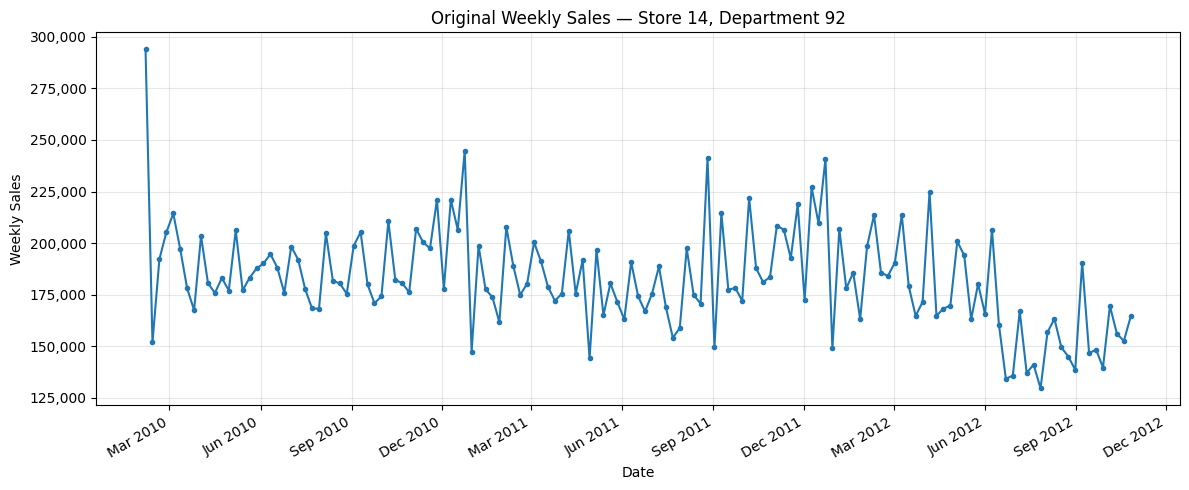

In [ ]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(weekly.index, weekly.values, color="tab:blue", linewidth=1.5, marker="o", markersize=3)

ax.set_title(f"Original Weekly Sales — Store {SELECTED_STORE}, Department {SELECTED_DEPT}")
ax.set_xlabel("Date")
ax.set_ylabel("Weekly Sales")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.grid(True, alpha=0.3)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

##  Calculate 4-Week Moving Average


In [ ]:
ma4 = weekly.rolling(window=4).mean()

print("First valid 4-week MA at:", ma4.first_valid_index().date())
print("Number of weeks without a 4-week MA value:", ma4.isna().sum())
ma4.dropna().head()

First valid 4-week MA at: 2010-02-26
Number of weeks without a 4-week MA value: 3


,Weekly_Sales
Date,
2010-02-26,"210,850.10"
2010-03-05,"190,954.36"
2010-03-12,"202,246.61"
2010-03-19,"198,683.21"
2010-03-26,"189,248.63"


##  Calculate 8-Week Moving Average


In [ ]:
ma8 = weekly.rolling(window=8).mean()

print("First valid 8-week MA at:", ma8.first_valid_index().date())
print("Number of weeks without an 8-week MA value:", ma8.isna().sum())
ma8.dropna().head()

First valid 8-week MA at: 2010-03-26
Number of weeks without an 8-week MA value: 7


,Weekly_Sales
Date,
2010-03-26,"200,049.37"
2010-04-02,"188,735.79"
2010-04-09,"192,321.18"
2010-04-16,"190,266.36"
2010-04-23,"187,503.42"


In [ ]:
# Combine everything into one DataFrame for easy inspection
result = pd.DataFrame({"Weekly_Sales": weekly, "MA_4": ma4, "MA_8": ma8})
result.head(12)

,Weekly_Sales,MA_4,MA_8
Date,,,
2010-02-05,"293,966.05",NaN,NaN
2010-02-12,"151,901.21",NaN,NaN
2010-02-19,"192,282.19",NaN,NaN
2010-02-26,"205,250.96","210,850.10",NaN
2010-03-05,"214,383.07","190,954.36",NaN
2010-03-12,"197,070.21","202,246.61",NaN
2010-03-19,"178,028.58","198,683.21",NaN
2010-03-26,"167,512.67","189,248.63","200,049.37"
2010-04-02,"203,457.42","186,517.22","188,735.79"


##  Plot Weekly Sales + Moving Averages

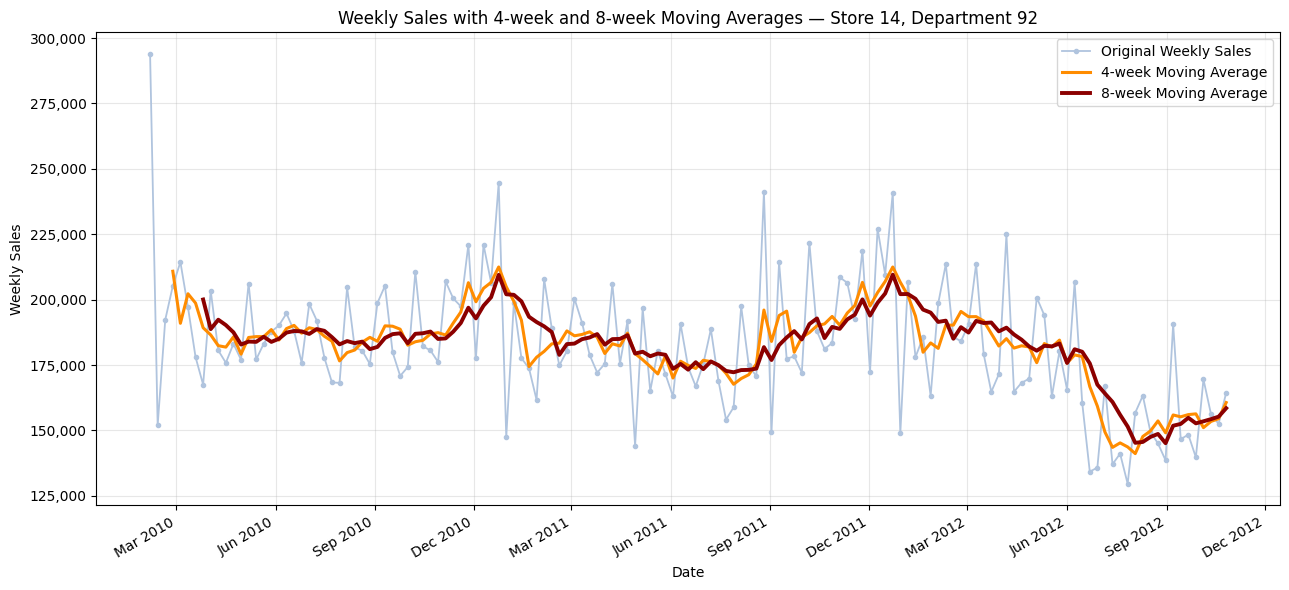

In [ ]:
fig, ax = plt.subplots(figsize=(13, 6))

ax.plot(weekly.index, weekly.values, color="lightsteelblue", linewidth=1.3,
        marker="o", markersize=3, label="Original Weekly Sales")
ax.plot(ma4.index, ma4.values, color="darkorange", linewidth=2.2, label="4-week Moving Average")
ax.plot(ma8.index, ma8.values, color="darkred", linewidth=2.8, label="8-week Moving Average")

ax.set_title(f"Weekly Sales with 4-week and 8-week Moving Averages — Store {SELECTED_STORE}, Department {SELECTED_DEPT}")
ax.set_xlabel("Date")
ax.set_ylabel("Weekly Sales")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.grid(True, alpha=0.3)
ax.legend(loc="upper right")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

##  Trend Interpretation


In [ ]:
print(f"Mean Weekly Sales   : {weekly.mean():,.2f}")
print(f"Minimum Weekly Sales: {weekly.min():,.2f} (week of {weekly.idxmin().date()})")
print(f"Maximum Weekly Sales: {weekly.max():,.2f} (week of {weekly.idxmax().date()})")

by_year = weekly.groupby(weekly.index.year).agg(weeks="count", mean_weekly_sales="mean")
print("\nAverage Weekly Sales by calendar year:")
display(by_year)

Mean Weekly Sales   : 182,527.96
Minimum Weekly Sales: 129,580.31 (week of 2012-07-27)
Maximum Weekly Sales: 293,966.05 (week of 2010-02-05)

Average Weekly Sales by calendar year:


,weeks,mean_weekly_sales
Date,,
2010,48,"191,087.15"
2011,52,"185,184.01"
2012,43,"169,761.54"


In [ ]:
months_per_year = weekly.groupby(weekly.index.year).apply(lambda s: set(s.index.month))
common_months = sorted(set.intersection(*months_per_year.tolist()))
same_period = weekly[weekly.index.month.isin(common_months)]

print("Months present in every year:", common_months)
comp = same_period.groupby(same_period.index.year).agg(weeks="count", mean_weekly_sales="mean")
comp["change_vs_previous_year_%"] = comp["mean_weekly_sales"].pct_change() * 100
print("\nAverage Weekly Sales in the same months of each year:")
display(comp)

Months present in every year: [2, 3, 4, 5, 6, 7, 8, 9, 10]

Average Weekly Sales in the same months of each year:


,weeks,mean_weekly_sales,change_vs_previous_year_%
Date,,,
2010,39,"188,432.51",NaN
2011,39,"181,856.90",-3.49
2012,39,"168,357.56",-7.42


In [ ]:
ma8_valid = ma8.dropna()
print(f"First 8-week MA value ({ma8_valid.index[0].date()}): {ma8_valid.iloc[0]:,.2f}")
print(f"Last 8-week MA value  ({ma8_valid.index[-1].date()}): {ma8_valid.iloc[-1]:,.2f}")
print(f"Highest 8-week MA     ({ma8_valid.idxmax().date()}): {ma8_valid.max():,.2f}")
print(f"Lowest 8-week MA      ({ma8_valid.idxmin().date()}): {ma8_valid.min():,.2f}")

print("\nAverage 8-week MA by quarter:")
display(ma8_valid.groupby([ma8_valid.index.year, ma8_valid.index.quarter]).mean().rename("mean_MA_8").to_frame())

First 8-week MA value (2010-03-26): 200,049.37
Last 8-week MA value  (2012-10-26): 158,500.51
Highest 8-week MA     (2011-12-23): 209,540.89
Lowest 8-week MA      (2012-08-31): 145,113.94

Average 8-week MA by quarter:


mean_MA_8
Date Date           
2010 1    200,049.37
     2    186,728.33
     3    185,080.01
     4    192,432.91
2011 1    188,820.13
     2    179,502.01
     3    177,804.29
     4    195,437.68
2012 1    192,397.56
     2    180,845.47
     3    152,036.29
     4    155,396.45

### Trend interpretation (based on the output above)

Looking at the actual numbers and the plot for the selected Store + Department:

- The original series does **not** move in a straight line; it fluctuates from week to week around a general level.
- The yearly averages and — more fairly — the same-months comparison show that average Weekly Sales are **lower in each successive year**. The 8-week Moving Average also ends at a lower level than where it starts and its lowest values occur late in the observation period.
- So the data **supports a gradual downward drift** in Weekly Sales over the observed period, with temporary rises along the way (visible in the moving averages), rather than a steady increase or a perfectly stable level.

How the moving averages help: the original weekly line is jagged, which makes the direction hard to read by eye. The moving averages remove much of the week-to-week movement, so the overall direction — and the temporary rises and falls around it — becomes clearly visible.



##  Noise Discussion



In [ ]:
noise = pd.DataFrame({
    "Series": ["Original Weekly Sales", "4-week Moving Average", "8-week Moving Average"],
    "Std of week-to-week change": [
        weekly.diff().std(),
        ma4.diff().std(),
        ma8.diff().std(),
    ],
})
noise["Relative to original (%)"] = noise["Std of week-to-week change"] / noise.loc[0, "Std of week-to-week change"] * 100
noise

,Series,Std of week-to-week change,Relative to original (%)
0,Original Weekly Sales,"31,391.09",100.00
1,4-week Moving Average,"5,784.89",18.43
2,8-week Moving Average,"3,669.58",11.69


In [ ]:
jumps = weekly.diff().abs().nlargest(5).rename("abs_change_from_previous_week").to_frame()
jumps["Weekly_Sales"] = weekly.loc[jumps.index]
jumps["IsHoliday"] = series_df.set_index("Date")["IsHoliday"].reindex(jumps.index)
jumps

,abs_change_from_previous_week,Weekly_Sales,IsHoliday
Date,,,
2010-02-12,"142,064.84","151,901.21",True
2010-12-31,"97,164.67","147,464.09",True
2011-12-30,"91,938.85","148,956.43",True
2011-09-02,"91,700.09","149,419.91",False
2011-08-26,"70,429.02","241,120.00",False


### Noise interpretation (based on the output above)

- The original Weekly Sales series shows **clear short-term fluctuations**: values often change noticeably from one week to the next, which hides the underlying direction.
- The **4-week Moving Average** has a much smaller week-to-week variation than the original series, so it smooths a good part of this noise while still following changes fairly closely.
- The **8-week Moving Average** is smoother still, so the broader direction is clearest here — at the cost of reacting later.
- Some of the largest week-to-week jumps can be checked against the `IsHoliday` flag in the table above. This shows that part of the fluctuation may be related to specific weeks, but the notebook does not claim to explain every fluctuation.

##  Seasonality Discussion


In [ ]:
month_tbl = weekly.groupby(weekly.index.month).agg(
    weeks="count", mean_weekly_sales="mean"
)
month_tbl["years_covered"] = weekly.groupby(weekly.index.month).apply(lambda s: s.index.year.nunique())
month_tbl.index.name = "Month"
display(month_tbl)

,weeks,mean_weekly_sales,years_covered
Month,,,
1,8,"180,708.38",2
2,12,"198,124.12",3
3,13,"186,085.17",3
4,14,"181,480.80",3
5,12,"183,841.59",3
6,13,"172,791.80",3
7,14,"166,105.26",3
8,13,"175,349.30",3
9,13,"174,752.64",3


In [ ]:
# Compare the same calendar months year by year (rows = month, columns = year)
pivot = weekly.groupby([weekly.index.month.rename("Month"), weekly.index.year.rename("Year")]).mean().unstack("Year")
display(pivot)

Year,2010,2011,2012
Month,,,
1,NaN,"177,966.42","183,450.34"
2,"210,850.10","188,039.66","195,482.60"
3,"189,248.63","185,630.32","183,918.28"
4,"184,009.43","178,598.15","181,923.32"
5,"188,549.66","178,448.73","184,526.37"
6,"187,184.64","173,700.80","160,550.33"
7,"180,932.59","169,214.67","143,684.33"
8,"185,576.36","196,026.09","150,626.22"
9,"188,699.15","178,330.52","156,333.77"


In [ ]:
# The highest-sales weeks and whether they are flagged as holiday weeks
top_weeks = weekly.nlargest(10).rename("Weekly_Sales").to_frame()
top_weeks["IsHoliday"] = series_df.set_index("Date")["IsHoliday"].reindex(top_weeks.index)
top_weeks.sort_index()

,Weekly_Sales,IsHoliday
Date,,
2010-02-05,"293,966.05",False
2010-11-26,"221,034.84",True
2010-12-10,"221,013.44",False
2010-12-24,"244,628.76",False
2011-08-26,"241,120.00",False
2011-10-07,"221,834.28",False
2011-11-25,"218,755.14",True
2011-12-09,"227,088.13",False
2011-12-23,"240,895.28",False


In [ ]:
for yr in sorted(weekly.index.year.unique()):
    dec = ma8[(ma8.index.year == yr) & (ma8.index.month == 12)].dropna()
    if len(dec) > 0:
        print(f"{yr}: average 8-week MA in December = {dec.mean():,.2f}")
    else:
        print(f"{yr}: no December observations available")

2010: average 8-week MA in December = 200,591.31
2011: average 8-week MA in December = 201,340.59
2012: no December observations available


---
# ACF + Stationarity



##  Prepare the Series



In [ ]:
# Copy of the Person 1 weekly series without NaN (the original `weekly` stays untouched)
stationary_input = weekly.dropna()

n_dropped = len(weekly) - len(stationary_input)
print(f"Series used: Store {SELECTED_STORE}, Department {SELECTED_DEPT}")
print(f"Observations in Person 1 weekly series : {len(weekly)}")
print(f"Missing values dropped for Person 2    : {n_dropped}")
print(f"Observations used for Person 2         : {len(stationary_input)}")
if n_dropped > 0:
    print("Note: weeks were dropped, not filled. Lags after a gap are no longer exactly 'n weeks apart'.")
else:
    print("No missing values, so the series is used exactly as created in Person 1.")

# Number of lags: up to 52 weeks (one year) when the series is long enough
acf_lags = min(52, len(stationary_input) // 2 - 1)
print(f"\nNumber of lags used for ACF/PACF plots: {acf_lags}")

Series used: Store 14, Department 92
Observations in Person 1 weekly series : 143
Missing values dropped for Person 2    : 0
Observations used for Person 2         : 143
No missing values, so the series is used exactly as created in Person 1.

Number of lags used for ACF/PACF plots: 52


##  ACF — Original Weekly Series



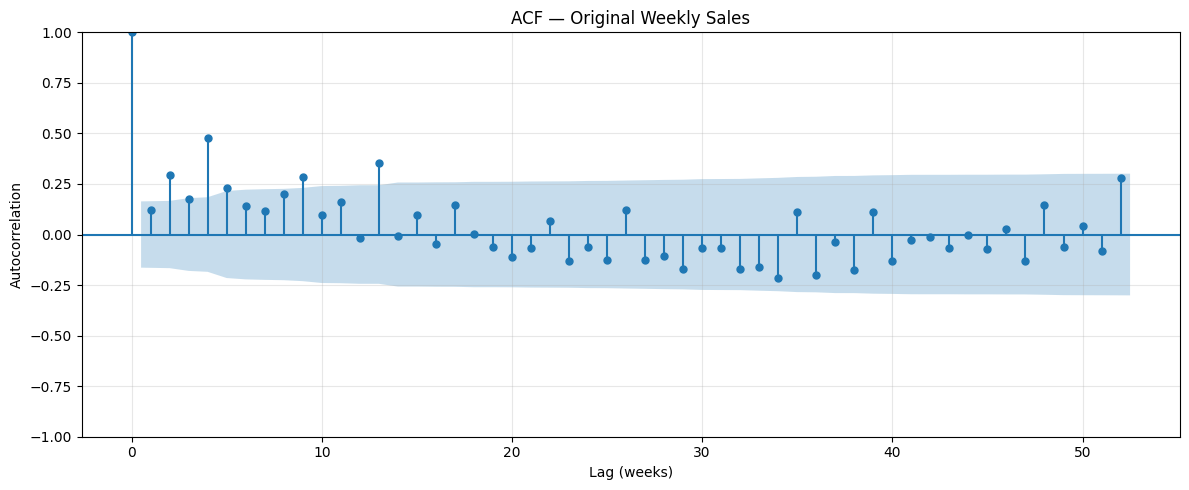

In [ ]:
fig, ax = plt.subplots(figsize=(12, 5))
plot_acf(stationary_input, lags=acf_lags, ax=ax, title="ACF — Original Weekly Sales")
ax.set_xlabel("Lag (weeks)")
ax.set_ylabel("Autocorrelation")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# Numbers behind the ACF plot (nothing assumed in advance)
acf_orig_values, acf_orig_conf = acf(stationary_input, nlags=acf_lags, alpha=0.05)
acf_orig_sig = [k for k in range(1, acf_lags + 1)
                if acf_orig_conf[k][0] > 0 or acf_orig_conf[k][1] < 0]   # confidence band excludes 0

print(f"Autocorrelation at lag 1 : {acf_orig_values[1]:.3f}")
print(f"Autocorrelation at lag 4 : {acf_orig_values[4]:.3f}")
print(f"Autocorrelation at lag 8 : {acf_orig_values[8]:.3f}")
print(f"Lags (out of {acf_lags}) outside the 95% band: {len(acf_orig_sig)}")
print("Those lags:", acf_orig_sig)

Autocorrelation at lag 1 : 0.122
Autocorrelation at lag 4 : 0.478
Autocorrelation at lag 8 : 0.201
Lags (out of 52) outside the 95% band: 5
Those lags: [2, 4, 5, 9, 13]


/tmp/ipykernel_2144/235125917.py:2: FutureWarning: acf currently returns a plain tuple whose length depends on the qstat and alpha arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an AcfResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  acf_orig_values, acf_orig_conf = acf(stationary_input, nlags=acf_lags, alpha=0.05)


##  Augmented Dickey-Fuller (ADF) Test — Original Series


In [ ]:
def run_adf_test(series, label, alpha=0.05):
    """ADF test. H0: non-stationary. p < alpha -> stationary."""
    stat, p_value, used_lag, n_obs, crit_values, _ = adfuller(series, autolag="AIC")
    is_stationary = p_value < alpha
    decision = "Reject H0" if is_stationary else "Do not reject H0"
    interpretation = ("evidence that the series is STATIONARY" if is_stationary
                      else "evidence that the series is NON-STATIONARY")
    print(f"ADF test — {label}")
    print(f"  ADF statistic    : {stat:.4f}")
    print(f"  p-value          : {p_value:.4f}")
    print(f"  Lags used (AIC)  : {used_lag}")
    print(f"  Observations     : {n_obs}")
    print(f"  Critical values  : " + ", ".join(f"{k}: {v:.3f}" for k, v in crit_values.items()))
    print(f"  Decision         : {decision} (p-value {'<' if is_stationary else '>='} {alpha})")
    print(f"  Interpretation   : {interpretation}")
    return {"statistic": stat, "p_value": p_value, "stationary": is_stationary,
            "decision": decision, "interpretation": interpretation}

adf_result = run_adf_test(stationary_input, "Original weekly sales")

ADF test — Original weekly sales
  ADF statistic    : -1.1920
  p-value          : 0.6770
  Lags used (AIC)  : 13
  Observations     : 129
  Critical values  : 1%: -3.482, 5%: -2.884, 10%: -2.579
  Decision         : Do not reject H0 (p-value >= 0.05)
  Interpretation   : evidence that the series is NON-STATIONARY


/tmp/ipykernel_2144/2582544692.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  stat, p_value, used_lag, n_obs, crit_values, _ = adfuller(series, autolag="AIC")


##  KPSS Test — Original Series



In [ ]:
def run_kpss_test(series, label, alpha=0.05):
    """KPSS test. H0: stationary. p < alpha -> non-stationary."""
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", InterpolationWarning)
        stat, p_value, used_lag, crit_values = kpss(series, regression="c", nlags="auto")
    table_note = any(issubclass(w.category, InterpolationWarning) for w in caught)
    is_stationary = p_value >= alpha
    decision = "Do not reject H0" if is_stationary else "Reject H0"
    interpretation = ("evidence consistent with STATIONARITY" if is_stationary
                      else "evidence that the series is NON-STATIONARY")
    print(f"KPSS test — {label}")
    print(f"  KPSS statistic   : {stat:.4f}")
    print(f"  p-value          : {p_value:.4f}")
    print(f"  Lags used        : {used_lag}")
    print(f"  Critical values  : " + ", ".join(f"{k}: {v:.3f}" for k, v in crit_values.items()))
    print(f"  Decision         : {decision} (p-value {'>=' if is_stationary else '<'} {alpha})")
    print(f"  Interpretation   : {interpretation}")
    if table_note:
        print("  Note: the true p-value lies outside the statsmodels lookup table (0.01 - 0.10); the value shown is its bound.")
    return {"statistic": stat, "p_value": p_value, "stationary": is_stationary,
            "decision": decision, "interpretation": interpretation}

kpss_result = run_kpss_test(stationary_input, "Original weekly sales")

KPSS test — Original weekly sales
  KPSS statistic   : 0.7189
  p-value          : 0.0118
  Lags used        : 6
  Critical values  : 10%: 0.347, 5%: 0.463, 2.5%: 0.574, 1%: 0.739
  Decision         : Reject H0 (p-value < 0.05)
  Interpretation   : evidence that the series is NON-STATIONARY


##  Combine ADF + KPSS — Overall Stationarity Decision



In [ ]:
def combine_stationarity_decisions(adf_res, kpss_res):
    if adf_res["stationary"] and kpss_res["stationary"]:
        return "STATIONARY", "Strong evidence for stationarity (both tests agree)."
    if (not adf_res["stationary"]) and (not kpss_res["stationary"]):
        return "NON-STATIONARY", "Strong evidence for non-stationarity (both tests agree)."
    return "MIXED / INCONCLUSIVE", "The two tests disagree, so the evidence is mixed."

overall_decision, overall_reason = combine_stationarity_decisions(adf_result, kpss_result)

print(f"ADF  says: {'stationary' if adf_result['stationary'] else 'non-stationary'}  (p = {adf_result['p_value']:.4f})")
print(f"KPSS says: {'stationary' if kpss_result['stationary'] else 'non-stationary'}  (p = {kpss_result['p_value']:.4f})")
print()
print(f"Overall decision: {overall_decision}")
print(overall_reason)

ADF  says: non-stationary  (p = 0.6770)
KPSS says: non-stationary  (p = 0.0118)

Overall decision: NON-STATIONARY
Strong evidence for non-stationarity (both tests agree).


Using both tests together is more reliable than using one:

| ADF | KPSS | Interpretation |
|---|---|---|
| Stationary | Stationary | Strong evidence for stationarity |
| Non-stationary | Non-stationary | Strong evidence for non-stationarity |
| Stationary | Non-stationary | Mixed / inconclusive |
| Non-stationary | Stationary | Mixed / inconclusive |

The overall decision below is derived from the two calculated results above.

##  Differencing



In [ ]:
if overall_decision == "NON-STATIONARY":
    needs_differencing = True
    differencing_reason = "both tests indicate non-stationarity"
elif overall_decision == "MIXED / INCONCLUSIVE" and not adf_result["stationary"]:
    needs_differencing = True
    differencing_reason = "tests are mixed, and ADF could not reject the unit-root null"
else:
    needs_differencing = False
    differencing_reason = ("the series is stationary" if overall_decision == "STATIONARY"
                           else "tests are mixed, but ADF already indicates stationarity")

print(f"First differencing needed: {needs_differencing} ({differencing_reason})")

weekly_diff = None
if needs_differencing:
    weekly_diff = stationary_input.diff().dropna()   # current value - previous value
    weekly_diff.name = "Weekly_Sales_diff"
    print(f"\nOriginal series length    : {len(stationary_input)}")
    print(f"Differenced series length : {len(weekly_diff)}  (the first week has no previous week, so it is lost)")
    display(weekly_diff.head())
else:
    print("\nDifferencing skipped. The original series is used as it is.")

First differencing needed: True (both tests indicate non-stationarity)

Original series length    : 143
Differenced series length : 142  (the first week has no previous week, so it is lost)


,Weekly_Sales_diff
Date,
2010-02-12,"-142,064.84"
2010-02-19,"40,380.98"
2010-02-26,"12,968.77"
2010-03-05,"9,132.11"
2010-03-12,"-17,312.86"


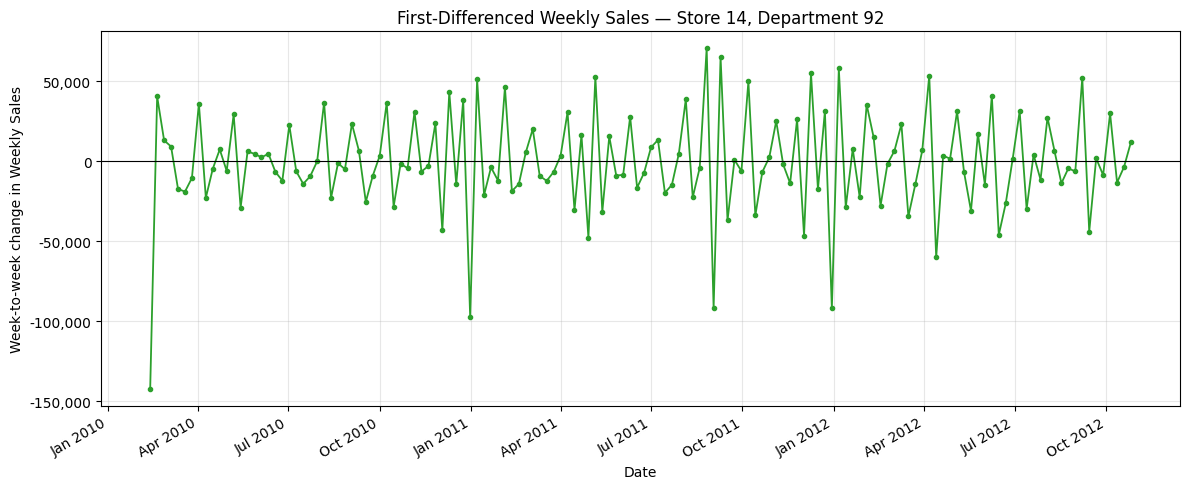

In [ ]:
if needs_differencing:
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(weekly_diff.index, weekly_diff.values, color="tab:green", linewidth=1.3, marker="o", markersize=3)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title(f"First-Differenced Weekly Sales — Store {SELECTED_STORE}, Department {SELECTED_DEPT}")
    ax.set_xlabel("Date")
    ax.set_ylabel("Week-to-week change in Weekly Sales")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    ax.grid(True, alpha=0.3)
    fig.autofmt_xdate()
    plt.tight_layout()
    plt.show()
else:
    print("Skipped: differencing was not required.")

##  ADF + KPSS After Differencing



In [ ]:
adf_result_diff = None
kpss_result_diff = None
overall_decision_diff = None

if needs_differencing:
    adf_result_diff = run_adf_test(weekly_diff, "First-differenced weekly sales")
    print()
    kpss_result_diff = run_kpss_test(weekly_diff, "First-differenced weekly sales")
    print()
    overall_decision_diff, overall_reason_diff = combine_stationarity_decisions(adf_result_diff, kpss_result_diff)
    print(f"Overall decision (after differencing): {overall_decision_diff}")
    print(overall_reason_diff)
    print()
    if overall_decision_diff == "STATIONARY":
        print("Conclusion: the first-differenced series is stationary.")
    elif overall_decision_diff == "NON-STATIONARY":
        print("Conclusion: the first-differenced series is still non-stationary; further treatment would be needed (not done here).")
    else:
        print("Conclusion: the first-differenced series gives mixed evidence; it is not clearly stationary.")
else:
    print("Skipped: the original series did not need differencing.")

ADF test — First-differenced weekly sales
  ADF statistic    : -4.8666
  p-value          : 0.0000
  Lags used (AIC)  : 11
  Observations     : 130
  Critical values  : 1%: -3.482, 5%: -2.884, 10%: -2.579
  Decision         : Reject H0 (p-value < 0.05)
  Interpretation   : evidence that the series is STATIONARY

KPSS test — First-differenced weekly sales
  KPSS statistic   : 0.2038
  p-value          : 0.1000
  Lags used        : 20
  Critical values  : 10%: 0.347, 5%: 0.463, 2.5%: 0.574, 1%: 0.739
  Decision         : Do not reject H0 (p-value >= 0.05)
  Interpretation   : evidence consistent with STATIONARITY
  Note: the true p-value lies outside the statsmodels lookup table (0.01 - 0.10); the value shown is its bound.

Overall decision (after differencing): STATIONARY
Strong evidence for stationarity (both tests agree).

Conclusion: the first-differenced series is stationary.


/tmp/ipykernel_2144/2582544692.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  stat, p_value, used_lag, n_obs, crit_values, _ = adfuller(series, autolag="AIC")


##  ACF — First-Differenced Weekly Sales



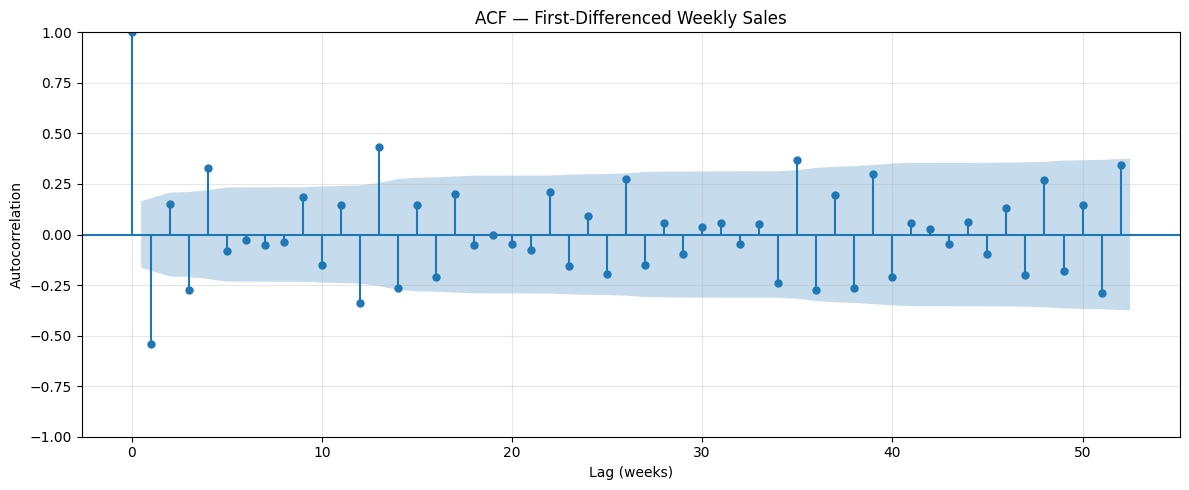

/tmp/ipykernel_2144/593227265.py:10: FutureWarning: acf currently returns a plain tuple whose length depends on the qstat and alpha arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an AcfResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  acf_diff_values, acf_diff_conf = acf(weekly_diff, nlags=acf_lags, alpha=0.05)


,Original series,First-differenced series
ACF at lag 1,0.122,-0.542
ACF at lag 4,0.478,0.330
ACF at lag 8,0.201,-0.036
Lags outside 95% band (of 52),5,6


Significant lags after differencing: [1, 3, 4, 12, 13, 35]


In [ ]:
if needs_differencing:
    fig, ax = plt.subplots(figsize=(12, 5))
    plot_acf(weekly_diff, lags=acf_lags, ax=ax, title="ACF — First-Differenced Weekly Sales")
    ax.set_xlabel("Lag (weeks)")
    ax.set_ylabel("Autocorrelation")
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    acf_diff_values, acf_diff_conf = acf(weekly_diff, nlags=acf_lags, alpha=0.05)
    acf_diff_sig = [k for k in range(1, acf_lags + 1)
                    if acf_diff_conf[k][0] > 0 or acf_diff_conf[k][1] < 0]

    comparison = pd.DataFrame({
        "Original series": [acf_orig_values[1], acf_orig_values[4], acf_orig_values[8], len(acf_orig_sig)],
        "First-differenced series": [acf_diff_values[1], acf_diff_values[4], acf_diff_values[8], len(acf_diff_sig)],
    }, index=["ACF at lag 1", "ACF at lag 4", "ACF at lag 8", f"Lags outside 95% band (of {acf_lags})"], dtype=object)
    comparison.iloc[:3] = comparison.iloc[:3].map(lambda v: f"{v:.3f}")
    display(comparison)
    print("Significant lags after differencing:", acf_diff_sig)
else:
    print("Skipped: differencing was not required.")

##  PACF — First-Differenced Weekly Sales


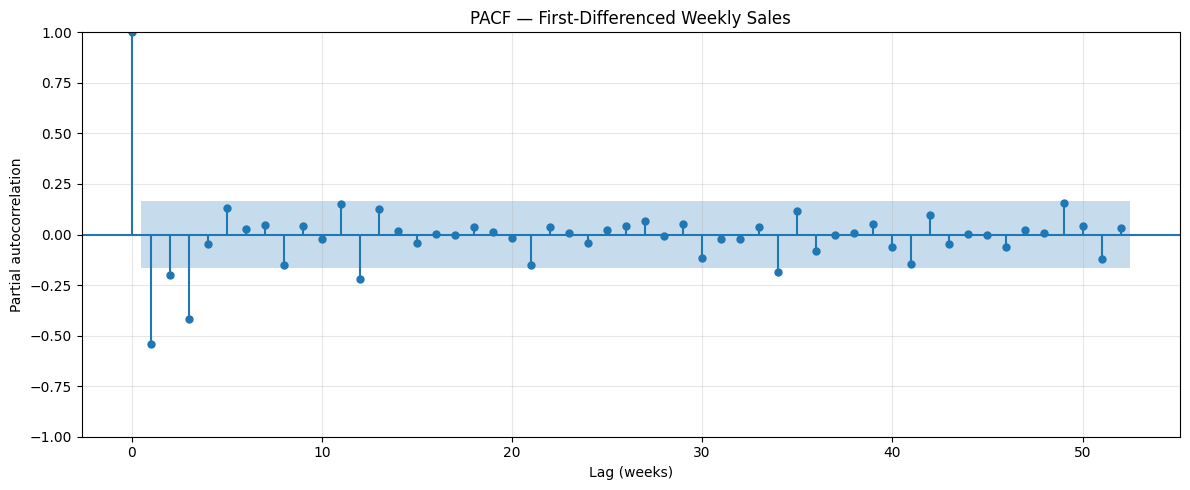

Approximate 95% band: +/- 0.164
Partial autocorrelation at lag 1: -0.542
Lags (out of 52) outside the band: 5
Those lags: [1, 2, 3, 12, 34]


In [ ]:
if needs_differencing:
    fig, ax = plt.subplots(figsize=(12, 5))
    plot_pacf(weekly_diff, lags=acf_lags, ax=ax, method="ywm", title="PACF — First-Differenced Weekly Sales")
    ax.set_xlabel("Lag (weeks)")
    ax.set_ylabel("Partial autocorrelation")
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    # Approximate 95% band for PACF: +/- 1.96 / sqrt(n)
    pacf_band = 1.96 / (len(weekly_diff) ** 0.5)
    from statsmodels.tsa.stattools import pacf as pacf_values_fn
    pacf_diff_values = pacf_values_fn(weekly_diff, nlags=acf_lags, method="ywm")
    pacf_diff_sig = [k for k in range(1, acf_lags + 1) if abs(pacf_diff_values[k]) > pacf_band]
    print(f"Approximate 95% band: +/- {pacf_band:.3f}")
    print(f"Partial autocorrelation at lag 1: {pacf_diff_values[1]:.3f}")
    print(f"Lags (out of {acf_lags}) outside the band: {len(pacf_diff_sig)}")
    print("Those lags:", pacf_diff_sig)
else:
    print("Skipped: differencing was not required.")

In [ ]:
# Live recap of every Person 2 result (all values come from the calculations above)
print(f"Series: Store {SELECTED_STORE}, Department {SELECTED_DEPT}, {len(stationary_input)} weekly observations")
print()
print(f"Original series  — ADF p = {adf_result['p_value']:.4f} ({'stationary' if adf_result['stationary'] else 'non-stationary'}), "
      f"KPSS p = {kpss_result['p_value']:.4f} ({'stationary' if kpss_result['stationary'] else 'non-stationary'})")
print(f"Overall decision: {overall_decision}")
print(f"First differencing applied: {needs_differencing}")
if needs_differencing:
    print(f"Differenced series — ADF p = {adf_result_diff['p_value']:.4f} ({'stationary' if adf_result_diff['stationary'] else 'non-stationary'}), "
          f"KPSS p = {kpss_result_diff['p_value']:.4f} ({'stationary' if kpss_result_diff['stationary'] else 'non-stationary'})")
    print(f"Overall decision after differencing: {overall_decision_diff}")
    print(f"ACF: {len(acf_orig_sig)} significant lags before vs {len(acf_diff_sig)} after differencing")
    print(f"PACF after differencing: significant lags = {pacf_diff_sig}")

Series: Store 14, Department 92, 143 weekly observations

Original series  — ADF p = 0.6770 (non-stationary), KPSS p = 0.0118 (non-stationary)
Overall decision: NON-STATIONARY
First differencing applied: True
Differenced series — ADF p = 0.0000 (stationary), KPSS p = 0.1000 (stationary)
Overall decision after differencing: STATIONARY
ACF: 5 significant lags before vs 6 after differencing
PACF after differencing: significant lags = [1, 2, 3, 12, 34]


---
# ARIMA + Random Forest

## Train / Test Split
Chronological 80 / 20 split (no shuffling), on the original series. `train_series` / `test_series` are used because `train` is already the raw DataFrame.

In [ ]:
split = int(len(stationary_input) * 0.8)
train_series = stationary_input.iloc[:split]
test_series  = stationary_input.iloc[split:]
h = len(test_series)
print(f"Train: {len(train_series)} weeks  ({train_series.index[0].date()} to {train_series.index[-1].date()})")
print(f"Test : {len(test_series)} weeks  ({test_series.index[0].date()} to {test_series.index[-1].date()})")
assert train_series.index.max() < test_series.index.min(), "train must end before test starts"
assert train_series.index.is_monotonic_increasing and test_series.index.is_monotonic_increasing
assert len(train_series) + len(test_series) == len(stationary_input)
print("Checks passed: chronological split, no overlap between train and test.")

Train: 114 weeks  (2010-02-05 to 2012-04-06)
Test : 29 weeks  (2012-04-13 to 2012-10-26)
Checks passed: chronological split, no overlap between train and test.


## ARIMA Models
Seven orders fitted on the training weeks only. Failed fits are recorded in the table, not skipped.

In [ ]:
orders = {
    "ARIMA(1,0,0)": (1, 0, 0),
    "ARIMA(1,0,1)": (1, 0, 1),
    "ARIMA(1,1,0)": (1, 1, 0),
    "ARIMA(0,1,1)": (0, 1, 1),
    "ARIMA(1,1,1)": (1, 1, 1),
    "ARIMA(2,0,1)": (2, 0, 1),
    "ARIMA(2,1,1)": (2, 1, 1),
}

arima_fits  = {}
arima_preds = {}
arima_aic, arima_bic = {}, {}
log_rows = []

for name, order in orders.items():
    try:
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            fit = ARIMA(train_series, order=order).fit()
            fc = pd.Series(np.asarray(fit.forecast(h)), index=test_series.index)
        if not np.isfinite(fc.values).all():
            raise ValueError("forecast contains NaN or infinite values")
        warn_names = sorted({w.category.__name__ for w in caught})
        arima_fits[name], arima_preds[name] = fit, fc
        arima_aic[name], arima_bic[name] = float(fit.aic), float(fit.bic)
        log_rows.append({"Model": name, "d": order[1], "Status": "OK",
                         "AIC": float(fit.aic), "BIC": float(fit.bic),
                         "Notes": ", ".join(warn_names) if warn_names else ""})
    except Exception as exc:
        arima_aic[name], arima_bic[name] = np.nan, np.nan
        log_rows.append({"Model": name, "d": order[1], "Status": "FAILED",
                         "AIC": np.nan, "BIC": np.nan,
                         "Notes": f"{type(exc).__name__}: {exc}"})

arima_results = pd.DataFrame(log_rows).set_index("Model")
display(arima_results)
print(f"Fitted successfully: {len(arima_fits)} of {len(orders)}")
print("Failed:", [n for n in orders if n not in arima_fits] or "none")

,d,Status,AIC,BIC,Notes
Model,,,,,
"ARIMA(1,0,0)",0,OK,"2,610.70","2,618.91",
"ARIMA(1,0,1)",0,OK,"2,609.18","2,620.12",
"ARIMA(1,1,0)",1,OK,"2,600.40","2,605.85",
"ARIMA(0,1,1)",1,OK,"2,574.37","2,579.83",
"ARIMA(1,1,1)",1,OK,"2,571.18","2,579.36",
"ARIMA(2,0,1)",0,OK,"2,611.15","2,624.83",
"ARIMA(2,1,1)",1,OK,"2,572.95","2,583.86",EstimationWarning


Fitted successfully: 7 of 7
Failed: none


AIC is only comparable between models with the same `d`; cross-`d` comparison is done on test errors by Person 4.

## Random Forest with Lag Features



In [ ]:
LAGS = [1, 2, 3]
RF_PARAMS = dict(n_estimators=300, min_samples_leaf=2, random_state=42)
def make_lag_frame(series, lags=LAGS):
    """Table with target y = Demand(t) and features lag1, lag2, lag3 = Demand(t-1), (t-2), (t-3)."""
    df = pd.DataFrame({"y": series})
    for l in lags:
        df[f"lag{l}"] = df["y"].shift(l)
    return df.dropna()
def rf_forecast(series, steps):
    """Fit a Random Forest on `series` only, then forecast `steps` weeks ahead recursively.
    Reusable by Person 4 (e.g. inside a rolling one-step forecast with steps=1)."""
    df = make_lag_frame(series)
    rf = RandomForestRegressor(**RF_PARAMS)
    rf.fit(df.drop(columns="y"), df["y"])
    history, out = list(series), []
    for _ in range(steps):
        x = pd.DataFrame([[history[-l] for l in LAGS]], columns=[f"lag{l}" for l in LAGS])
        pred = float(rf.predict(x)[0])
        out.append(pred)
        history.append(pred)
    return out
rf_train_frame = make_lag_frame(train_series)
assert rf_train_frame.index.max() == train_series.index[-1] and rf_train_frame.index.max() < test_series.index.min()
print(f"Training rows for the Random Forest: {len(rf_train_frame)} "
      f"(= {len(train_series)} train weeks - {max(LAGS)} weeks lost to lags)")
display(rf_train_frame.head())
rf_pred = pd.Series(rf_forecast(train_series, h), index=test_series.index)
rf_pred.name = "Random Forest"
print(f"Random Forest forecast: {len(rf_pred)} weeks, no missing values: {bool(rf_pred.notna().all())}")
rf_pred.head()

Training rows for the Random Forest: 111 (= 114 train weeks - 3 weeks lost to lags)


,y,lag1,lag2,lag3
Date,,,,
2010-02-26,"205,250.96","192,282.19","151,901.21","293,966.05"
2010-03-05,"214,383.07","205,250.96","192,282.19","151,901.21"
2010-03-12,"197,070.21","214,383.07","205,250.96","192,282.19"
2010-03-19,"178,028.58","197,070.21","214,383.07","205,250.96"
2010-03-26,"167,512.67","178,028.58","197,070.21","214,383.07"


Random Forest forecast: 29 weeks, no missing values: True


,Random Forest
Date,
2012-04-13,"182,087.27"
2012-04-20,"208,726.48"
2012-04-27,"194,115.25"
2012-05-04,"192,274.47"
2012-05-11,"193,131.81"


## Forecasts on the Test Period (visual check)



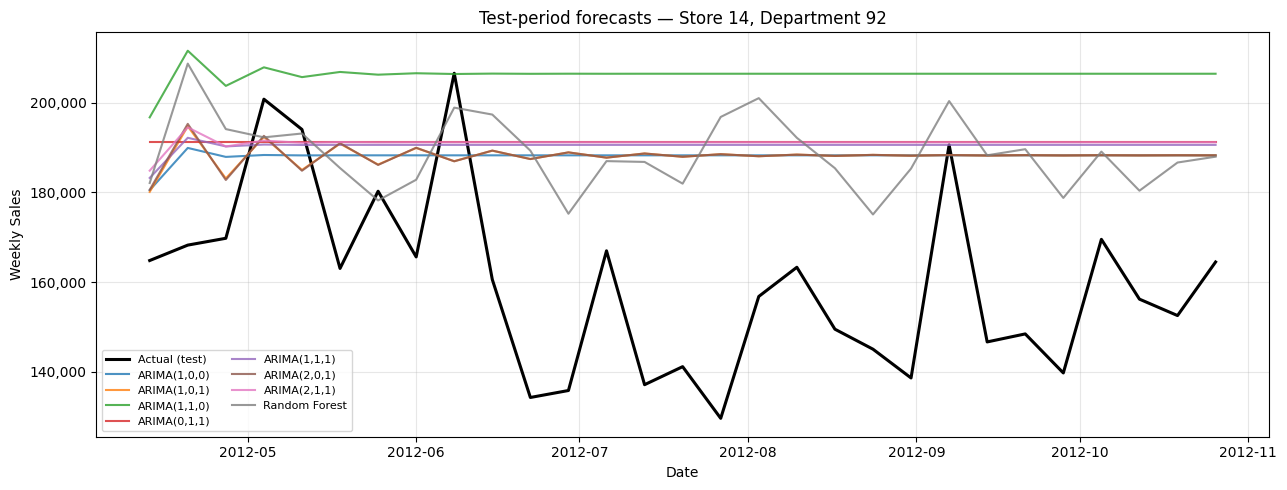

In [ ]:
preds = dict(arima_preds)
preds["Random Forest"] = rf_pred
aics = dict(arima_aic)
aics["Random Forest"] = np.nan
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(test_series.index, test_series.values, color="black", linewidth=2.2, label="Actual (test)")
for name, p in preds.items():
    ax.plot(p.index, p.values, alpha=0.8, linewidth=1.5, label=name)
ax.set_title(f"Test-period forecasts — Store {SELECTED_STORE}, Department {SELECTED_DEPT}")
ax.set_xlabel("Date"); ax.set_ylabel("Weekly Sales")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.grid(True, alpha=0.3); ax.legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.show()

In [ ]:
print("Models ready for evaluation:", list(preds))
print("Models without a forecast (failed):", [n for n in orders if n not in preds] or "none")

Models ready for evaluation: ['ARIMA(1,0,0)', 'ARIMA(1,0,1)', 'ARIMA(1,1,0)', 'ARIMA(0,1,1)', 'ARIMA(1,1,1)', 'ARIMA(2,0,1)', 'ARIMA(2,1,1)', 'Random Forest']
Models without a forecast (failed): none


In [ ]:
assert all(v in globals() for v in ["train_series", "test_series", "arima_fits", "preds", "rf_forecast"]), \
    "Run the Train/Test Split, ARIMA, Random Forest and forecast cells above first."
print(f"Using the split from above: train = {len(train_series)} weeks, test = {len(test_series)} weeks")

Using the split from above: train = 114 weeks, test = 29 weeks


---
#  Evaluation & Final Forecast for TrendPilot



In [ ]:
# ---------------------------------------------------------
# Section A: multi-step test-period evaluation (MAE, RMSE, AIC)
# ---------------------------------------------------------
evaluation_results = []

for name in orders:
    if name not in arima_fits:
        print(f"Skipping {name}: it failed to fit in the ARIMA section")
        continue
    p = preds[name]
    evaluation_results.append({
        "Model": name,
        "MAE":  mean_absolute_error(test_series, p),
        "RMSE": np.sqrt(mean_squared_error(test_series, p)),
        "AIC":  arima_aic[name],
        "BIC":  arima_bic[name],
    })

# Random Forest: the recursive forecast already computed above (rf_pred)
evaluation_results.append({
    "Model": "Random Forest",
    "MAE":  mean_absolute_error(test_series, preds["Random Forest"]),
    "RMSE": np.sqrt(mean_squared_error(test_series, preds["Random Forest"])),
    "AIC":  np.nan,
    "BIC":  np.nan,
})

df_eval = pd.DataFrame(evaluation_results).sort_values("RMSE").reset_index(drop=True)
print("=== Section A: Out-of-Sample Model Comparison Table ===")
display(df_eval.round(2))
print("Note: AIC/BIC are only comparable between models with the same d; Random Forest has no AIC.")

best_arima_name = df_eval[df_eval["Model"].str.startswith("ARIMA")].iloc[0]["Model"]
best_order = orders[best_arima_name]
print(f"\nBest ARIMA by test RMSE: {best_arima_name}")
print(f"Best model overall (multi-step): {df_eval.loc[0, 'Model']}")

=== Section A: Out-of-Sample Model Comparison Table ===


,Model,MAE,RMSE,AIC,BIC
0,Random Forest,"29,964.31","33,926.54",NaN,NaN
1,"ARIMA(1,0,0)","30,739.56","34,407.79","2,610.70","2,618.91"
2,"ARIMA(1,0,1)","30,835.07","34,562.70","2,609.18","2,620.12"
3,"ARIMA(2,0,1)","30,860.19","34,584.58","2,611.15","2,624.83"
4,"ARIMA(1,1,1)","32,437.75","36,336.44","2,571.18","2,579.36"
5,"ARIMA(2,1,1)","32,970.74","36,873.98","2,572.95","2,583.86"
6,"ARIMA(0,1,1)","33,243.72","37,092.97","2,574.37","2,579.83"
7,"ARIMA(1,1,0)","46,275.82","50,377.00","2,600.40","2,605.85"


Note: AIC/BIC are only comparable between models with the same d; Random Forest has no AIC.

Best ARIMA by test RMSE: ARIMA(1,0,0)
Best model overall (multi-step): Random Forest


In [ ]:
# ---------------------------------------------------------
# Section B: rolling one-step-ahead forecast
# ---------------------------------------------------------
def rolling_forecast(model_name):
    history = list(train_series.values)
    out = []
    for t in range(len(test_series)):
        if model_name == "Naive":
            out.append(history[-1])
        elif model_name == "Random Forest":
            out.append(rf_forecast(pd.Series(history), 1)[0])      # refit each step, same RF_PARAMS
        else:
            fit = ARIMA(history, order=orders[model_name]).fit()
            out.append(float(np.asarray(fit.forecast(1))[0]))
        history.append(test_series.iloc[t])                        # true value enters the history
    return pd.Series(out, index=test_series.index)

# 1. Naive baseline: next week = last week
preds_naive = rolling_forecast("Naive")
mae_naive  = mean_absolute_error(test_series, preds_naive)
rmse_naive = np.sqrt(mean_squared_error(test_series, preds_naive))
print(f"Naive MAE: {mae_naive:,.2f} | RMSE: {rmse_naive:,.2f}")

Naive MAE: 20,028.83 | RMSE: 25,988.44


In [ ]:
# 2. Rolling ARIMA: the three reference orders from the Nile notebook + the best ARIMA from Section A
rolling_arima_names = list(dict.fromkeys(["ARIMA(1,0,0)", "ARIMA(1,1,0)", "ARIMA(0,1,1)", best_arima_name]))
rolling_arima_names = [n for n in rolling_arima_names if n in arima_fits]

roll_preds = {"Naive": preds_naive}
for n in rolling_arima_names:
    roll_preds[n] = rolling_forecast(n)
    print(f"{n} rolling forecast done")

ARIMA(1,0,0) rolling forecast done
ARIMA(1,1,0) rolling forecast done
ARIMA(0,1,1) rolling forecast done


In [ ]:
# 3. Rolling Random Forest: refit on all history at every step, with the SAME RF_PARAMS as above
roll_preds["Random Forest"] = rolling_forecast("Random Forest")

mae_rf_roll  = mean_absolute_error(test_series, roll_preds["Random Forest"])
rmse_rf_roll = np.sqrt(mean_squared_error(test_series, roll_preds["Random Forest"]))
print(f"Rolling Random Forest MAE : {mae_rf_roll:,.2f}")
print(f"Rolling Random Forest RMSE: {rmse_rf_roll:,.2f}")

Rolling Random Forest MAE : 22,121.79
Rolling Random Forest RMSE: 26,179.99


=== Section B: Rolling One-Step-Ahead Forecast Evaluation ===


,Model,Rolling MAE,Rolling RMSE
0,"ARIMA(0,1,1)","17,587.81","21,431.04"
1,"ARIMA(1,1,0)","18,943.26","22,953.89"
2,Naive,"20,028.83","25,988.44"
3,Random Forest,"22,121.79","26,179.99"
4,"ARIMA(1,0,0)","29,102.35","32,899.23"


Best rolling ARIMA: ARIMA(0,1,1)
ARIMA(0,1,1): beats the Naive baseline (RMSE 21,431 vs 25,988)
ARIMA(1,1,0): beats the Naive baseline (RMSE 22,954 vs 25,988)
Random Forest: does NOT beat the Naive baseline (RMSE 26,180 vs 25,988)
ARIMA(1,0,0): does NOT beat the Naive baseline (RMSE 32,899 vs 25,988)


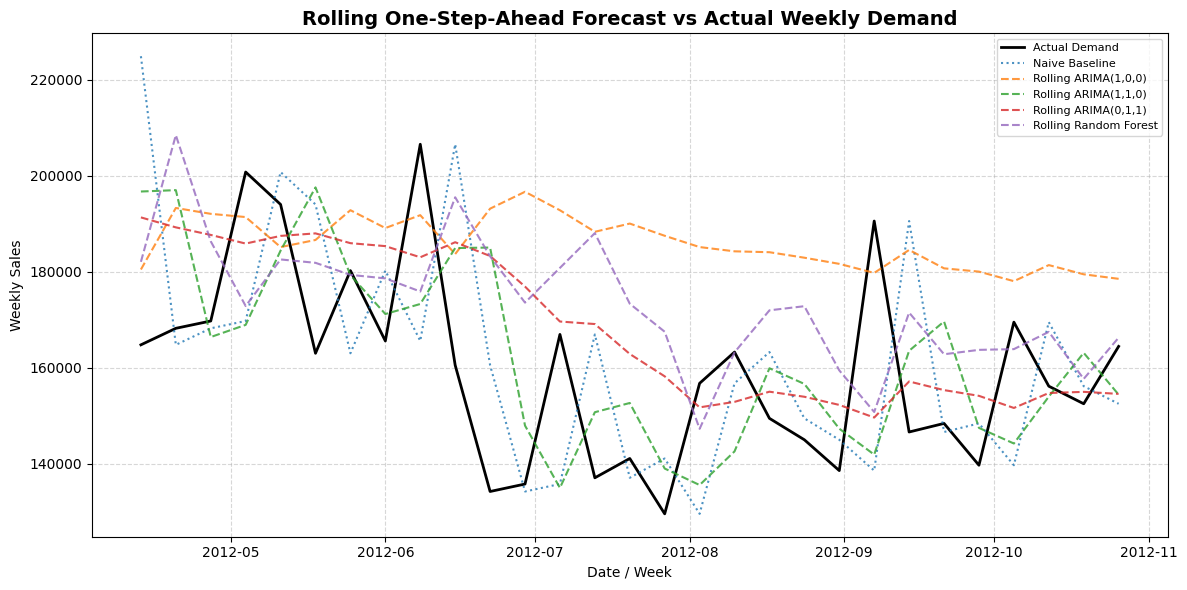

In [ ]:
# ---------------------------------------------------------
# 4. Comparison table & visualization
# ---------------------------------------------------------
roll_metrics = pd.DataFrame([{
    "Model": n,
    "Rolling MAE":  mean_absolute_error(test_series, p),
    "Rolling RMSE": np.sqrt(mean_squared_error(test_series, p)),
} for n, p in roll_preds.items()]).sort_values("Rolling RMSE").reset_index(drop=True)

print("=== Section B: Rolling One-Step-Ahead Forecast Evaluation ===")
display(roll_metrics.round(2))

# Best rolling ARIMA (used for the final forecast)
arima_roll = roll_metrics[roll_metrics["Model"].str.startswith("ARIMA")]
best_roll_arima_name = arima_roll.iloc[0]["Model"]
best_roll_order = orders[best_roll_arima_name]
rmse_arima_roll = arima_roll.iloc[0]["Rolling RMSE"]
mae_arima_roll  = arima_roll.iloc[0]["Rolling MAE"]
print(f"Best rolling ARIMA: {best_roll_arima_name}")

for n in roll_metrics["Model"]:
    if n != "Naive":
        r = roll_metrics.loc[roll_metrics["Model"] == n, "Rolling RMSE"].iloc[0]
        print(f"{n}: {'beats' if r < rmse_naive else 'does NOT beat'} the Naive baseline (RMSE {r:,.0f} vs {rmse_naive:,.0f})")

plt.figure(figsize=(12, 6))
plt.plot(test_series.index, test_series.values, label="Actual Demand", color="black", linewidth=2)
for n, p in roll_preds.items():
    plt.plot(p.index, p.values, alpha=0.8, linestyle="--" if n != "Naive" else ":", label=f"Rolling {n}" if n != "Naive" else "Naive Baseline")
plt.title("Rolling One-Step-Ahead Forecast vs Actual Weekly Demand", fontsize=14, fontweight="bold")
plt.xlabel("Date / Week"); plt.ylabel("Weekly Sales")
plt.legend(fontsize=8); plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout(); plt.show()

=== Section C: Residual Statistics (Random Forest, test period) ===
Residual Mean               : -28,643.95
Residual Standard Deviation : 18,502.41


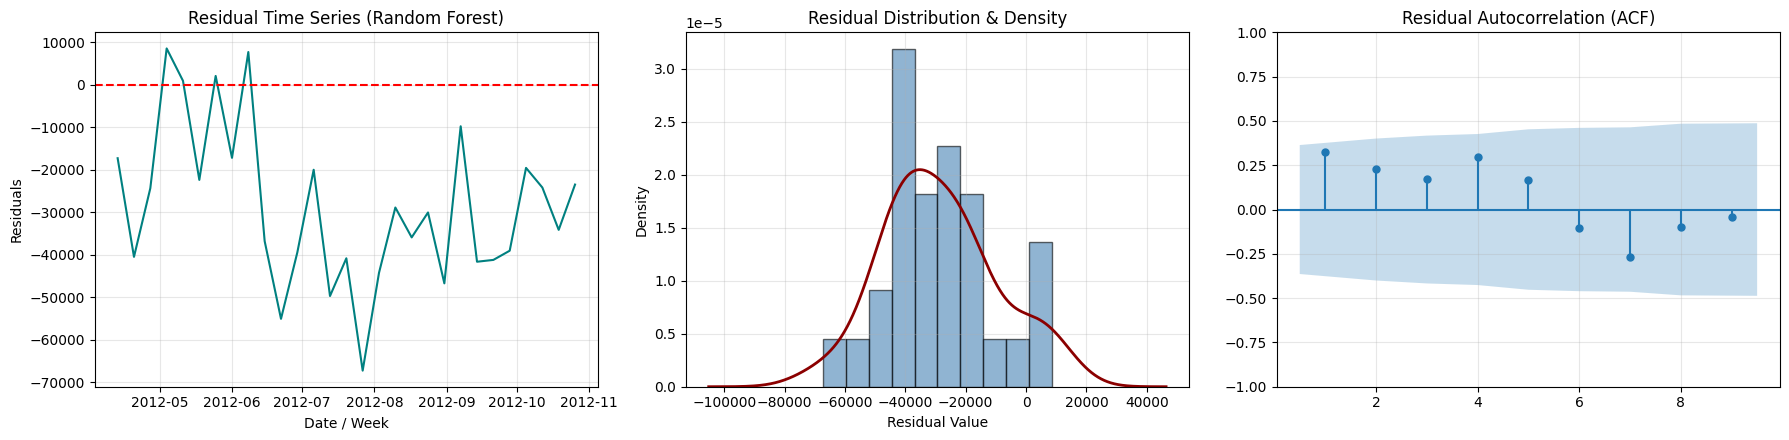

=== Ljung-Box Test Results (p < 0.05 -> autocorrelation left in residuals) ===


,lb_stat,lb_pvalue
4,9.27,0.05
8,14.12,0.08
12,23.09,0.03


In [ ]:
# ---------------------------------------------------------
# Section C: residuals of the best model on the test period (test - forecast)
# ---------------------------------------------------------
best_name = df_eval.loc[0, "Model"]
residuals = test_series - preds[best_name]

res_mean = residuals.mean()
res_std  = residuals.std()
print(f"=== Section C: Residual Statistics ({best_name}, test period) ===")
print(f"Residual Mean               : {res_mean:,.2f}")
print(f"Residual Standard Deviation : {res_std:,.2f}")

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

axes[0].plot(residuals, color="teal")
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_title(f"Residual Time Series ({best_name})")
axes[0].set_xlabel("Date / Week"); axes[0].set_ylabel("Residuals"); axes[0].grid(True, alpha=0.3)

axes[1].hist(residuals, bins=10, density=True, alpha=0.6, color="steelblue", edgecolor="black")
residuals.plot(kind="kde", ax=axes[1], color="darkred", linewidth=2)
axes[1].set_title("Residual Distribution & Density")
axes[1].set_xlabel("Residual Value"); axes[1].grid(True, alpha=0.3)

plot_acf(residuals, ax=axes[2], lags=min(10, len(residuals) // 3), zero=False, title="Residual Autocorrelation (ACF)")
axes[2].grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

# Ljung-Box test for remaining autocorrelation (only lags shorter than the sample)
lb_lags = [l for l in (4, 8, 12) if l < len(residuals) // 2]
lb_df = acorr_ljungbox(residuals, lags=lb_lags, return_df=True)
print("=== Ljung-Box Test Results (p < 0.05 -> autocorrelation left in residuals) ===")
display(lb_df)

In [ ]:
# ---------------------------------------------------------
# Section D: final 8-week forecast
# ---------------------------------------------------------
full_series = pd.concat([train_series, test_series]).astype(float)

# Select by rolling (out-of-sample) RMSE: best rolling ARIMA vs Random Forest
candidates = {best_roll_arima_name: rmse_arima_roll, "Random Forest": rmse_rf_roll}
selected_model_type = min(candidates, key=candidates.get)
print(f"Selected Best Model for Final Future Forecast: {selected_model_type}")
if min(candidates.values()) >= rmse_naive:
    print("WARNING: neither model beats the Naive baseline in the rolling evaluation.")

horizon = 8
future_dates = pd.date_range(start=full_series.index[-1] + pd.Timedelta(days=7), periods=horizon, freq="7D")  # keeps Walmart's weekly (Friday) dates

if selected_model_type.startswith("ARIMA"):
    final_fit = ARIMA(full_series, order=orders[selected_model_type]).fit()   # refit on the full series
    forecast_obj = final_fit.get_forecast(steps=horizon)
    point_forecast = pd.Series(np.asarray(forecast_obj.predicted_mean), index=future_dates)
    conf_int = np.asarray(forecast_obj.conf_int(alpha=0.05))
    lower_ci = pd.Series(conf_int[:, 0], index=future_dates)
    upper_ci = pd.Series(conf_int[:, 1], index=future_dates)
else:
    # Random Forest refit on the FULL series, recursive multi-step forecast
    point_forecast = pd.Series(rf_forecast(full_series, horizon), index=future_dates)
    lower_ci = pd.Series([np.nan] * horizon, index=future_dates)
    upper_ci = pd.Series([np.nan] * horizon, index=future_dates)

# Non-negative handling for realistic demand
point_forecast_clipped = np.maximum(0, point_forecast)

df_future_forecast = pd.DataFrame({
    "Forecast Week / Date": future_dates,
    "Predicted Demand (Raw)": point_forecast.values.round(2),
    "Operational Demand (Clipped >= 0)": point_forecast_clipped.values.round(2),
    "Lower 95% CI": lower_ci.values.round(2) if not lower_ci.isnull().all() else "N/A",
    "Upper 95% CI": upper_ci.values.round(2) if not upper_ci.isnull().all() else "N/A",
})
print("=== Section D: 8-Week Future Demand Forecast Table ===")
display(df_future_forecast)

plt.figure(figsize=(13, 6))
plt.plot(full_series.index, full_series.values, label="Historical Weekly Sales", color="navy", linewidth=2)
plt.plot(future_dates, point_forecast_clipped.values, label="8-Week Future Forecast", color="crimson", linewidth=2.5, linestyle="--")
if not lower_ci.isnull().all():
    plt.fill_between(future_dates, np.maximum(0, lower_ci.values), upper_ci.values, color="crimson", alpha=0.2, label="95% Confidence Interval")
plt.title(f"TrendPilot — 8-Week Demand Forecast ({selected_model_type})", fontsize=14, fontweight="bold")
plt.xlabel("Date / Week"); plt.ylabel("Weekly Sales")
plt.legend(loc="upper left"); plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout(); plt.show()

Selected Best Model for Final Future Forecast: ARIMA(0,1,1)
=== Section D: 8-Week Future Demand Forecast Table ===


,Forecast Week / Date,Predicted Demand (Raw),Operational Demand (Clipped >= 0),Lower 95% CI,Upper 95% CI
0,2012-11-02,"156,249.65","156,249.65","114,943.06","197,556.23"
1,2012-11-09,"156,249.65","156,249.65","114,355.41","198,143.88"
2,2012-11-16,"156,249.65","156,249.65","113,775.89","198,723.40"
3,2012-11-23,"156,249.65","156,249.65","113,204.18","199,295.11"
4,2012-11-30,"156,249.65","156,249.65","112,639.95","199,859.34"
5,2012-12-07,"156,249.65","156,249.65","112,082.94","200,416.35"
6,2012-12-14,"156,249.65","156,249.65","111,532.86","200,966.43"
7,2012-12-21,"156,249.65","156,249.65","110,989.47","201,509.82"


# EXTRA — Light additions beyond Section 2


## EXTRA 1 — Seasonal Naive + MASE scale

In [ ]:
SEASON = 52   # weeks in a year
extra_preds = {}

if len(train_series) >= SEASON:
    history, out = list(train_series.values), []
    for t in range(len(test_series)):
        out.append(history[-SEASON])              # same week last year
        history.append(test_series.iloc[t])       # true value enters the history
    extra_preds["Seasonal Naive (52w)"] = pd.Series(out, index=test_series.index)
    print("Seasonal Naive MAE :", f"{mean_absolute_error(test_series, extra_preds['Seasonal Naive (52w)']):,.2f}")
else:
    print(f"Skipped: need at least {SEASON} training weeks.")

# MASE scale = average one-step naive error on the TRAIN set only
mase_scale = np.mean(np.abs(np.diff(train_series.values)))
print(f"MASE scale (train naive MAE): {mase_scale:,.2f}")